# Figure 3 — Epistasis between the direct motifs and the other motifs of a peak

Shuffle-donor knockouts (`pipeline/03_epistasis`, ENCODE bigBed hits): **none** = direct and other motif bases taken
from a dinucleotide shuffle, **p0_only** = only the direct motifs kept, **non_only** = only the other motifs kept,
**wt** = intact. Predicted log counts, no control track, mean of 5 folds and 20 shuffles.

interaction = wt − (p0_only + non_only − none): > 0 synergy, < 0 redundancy.

Inputs: `data/examples/HepG2_FOXA1_ENCSR000BMO/` (step 03), the ENCODE models and bigBed of that experiment
(step 00), `data/epi_curves_pos.parquet` and `data/effect_curves_{direct,others}.parquet` (step 05).
The logo cells need a GPU.

In [1]:
import sys
sys.path.insert(0, '../modules')        # run from notebooks/
import paths                            # data root, genome, repo locations (env BPNET_DATA, MISHA_HG38)
from plot_setup import fig_path         # editable PDF text; figures/ in the repository
%config InlineBackend.figure_format = 'retina'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymisha as pm
from pypalettes import load_cmap
from plotnine import *
from plotnine_extensions import rasterise
from peaks import load_experiment, peak_interval, attribution_logo, gain_bars
from curves import TH_EFF, per_tf, plot_epi_curves, plot_rank, HIGHLIGHT

pm.gsetroot(paths.MISHA_HG38)
teals = load_cmap('Teal', cmap_type='continuous')

## FOXA1 (HepG2, ENCSR000BMO): a synergistic and an additive peak

In [3]:
foxa1 = load_experiment('HepG2/FOXA1_ENCSR000BMO', 'all')    # ALL_BPNET/HepG2/FOXA1_ENCSR000BMO

In [4]:
df = foxa1['epi']
df['d_dir'] = df.wt - df.non_only        # loss when only the direct motifs are shuffled
df['d_oth'] = df.wt - df.p0_only         # loss when only the other motifs are shuffled
df['z_int'] = df.interaction / df.interaction_sd

both = df[(df.n_p0 > 0) & (df.n_other > 0)]                   # both motif sets present
base = both[(both.d_dir > both.d_oth) & (both.d_dir > 0.5)]   # big direct deletion, bigger than the others'
classes = dict(synergy=base[(base.z_int > 2) & (base.interaction > 0.3)],
               redundant=base[(base.z_int < -2) & (base.interaction < -0.3)],
               additive=base[(base.z_int.abs() < 1) & (base.interaction.abs() < 0.1)])   # interaction ~ 0, within noise
print({k: len(v) for k, v in classes.items()})

key = lambda r: df.index[(df.chrom == r[0]) & (df.start == r[1])][0]
SYNERGY_PEAK = key(('chr1', 98085883))     # 10th-highest interaction among peaks with both motif sets (+1.60)
ADDITIVE_PEAK = key(('chr3', 76972037))    # 5th-strongest (by wt rank) peak of the additive class (+0.06)
assert SYNERGY_PEAK == both.sort_values('interaction', ascending=False).index[9]
assert ADDITIVE_PEAK == classes['additive'].sort_values('rank').index[4]
df.loc[[SYNERGY_PEAK, ADDITIVE_PEAK], ['chrom', 'start', 'end', 'rank', 'wt', 'none', 'p0_only', 'non_only',
                                       'additive', 'interaction', 'z_int']]

{'synergy': 9785, 'redundant': 40, 'additive': 4221}


,chrom,start,end,rank,wt,none,p0_only,non_only,additive,interaction,z_int
2028,chr1,98085883,98087997,1949.0,1.190561,-1.510912,-0.689605,-1.226964,-0.405657,1.596218,3.856708
31846,chr3,76972037,76974151,46.0,1.918277,-1.276959,0.948853,-0.364911,1.860901,0.057376,0.256137


/home/labs/barkailab/vovam/miniconda/envs/seqtfun031/lib/python3.12/site-packages/matplotlib_inline/config.py:74: DeprecationWarning: InlineBackend._figure_format_changed is deprecated in traitlets 4.1: use @observe and @unobserve instead.


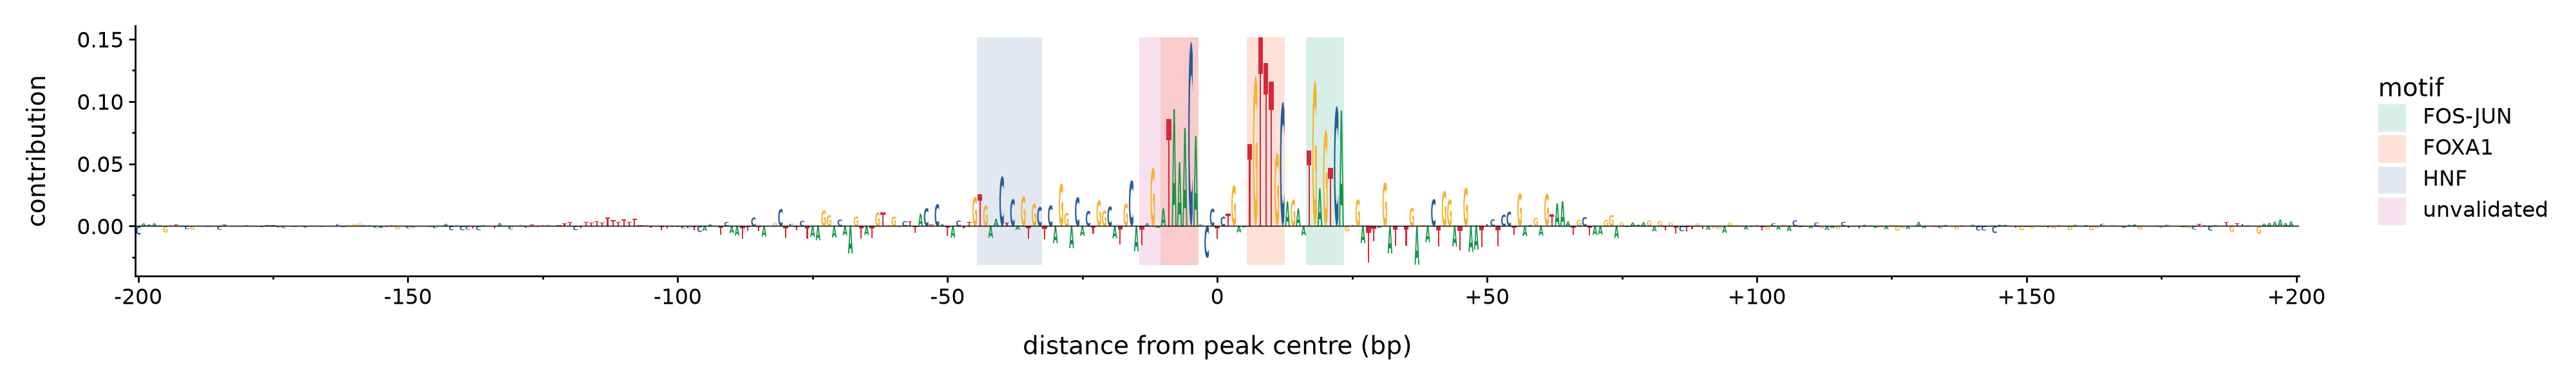

/home/labs/barkailab/vovam/miniconda/envs/seqtfun031/lib/python3.12/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 20 x 3 in image.
/home/labs/barkailab/vovam/miniconda/envs/seqtfun031/lib/python3.12/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: /home/labs/barkailab/vovam/submission_git/bpnet_grammar_paper/figures/FOXA1_self_vs_others_epi_synergy_seqlets.pdf


In [5]:
p = attribution_logo(peak_interval(df.loc[SYNERGY_PEAK]), foxa1['hits'], foxa1['cfolds'])      # GPU
p.show()
p.save(fig_path('FOXA1_self_vs_others_epi_synergy_seqlets.pdf'))

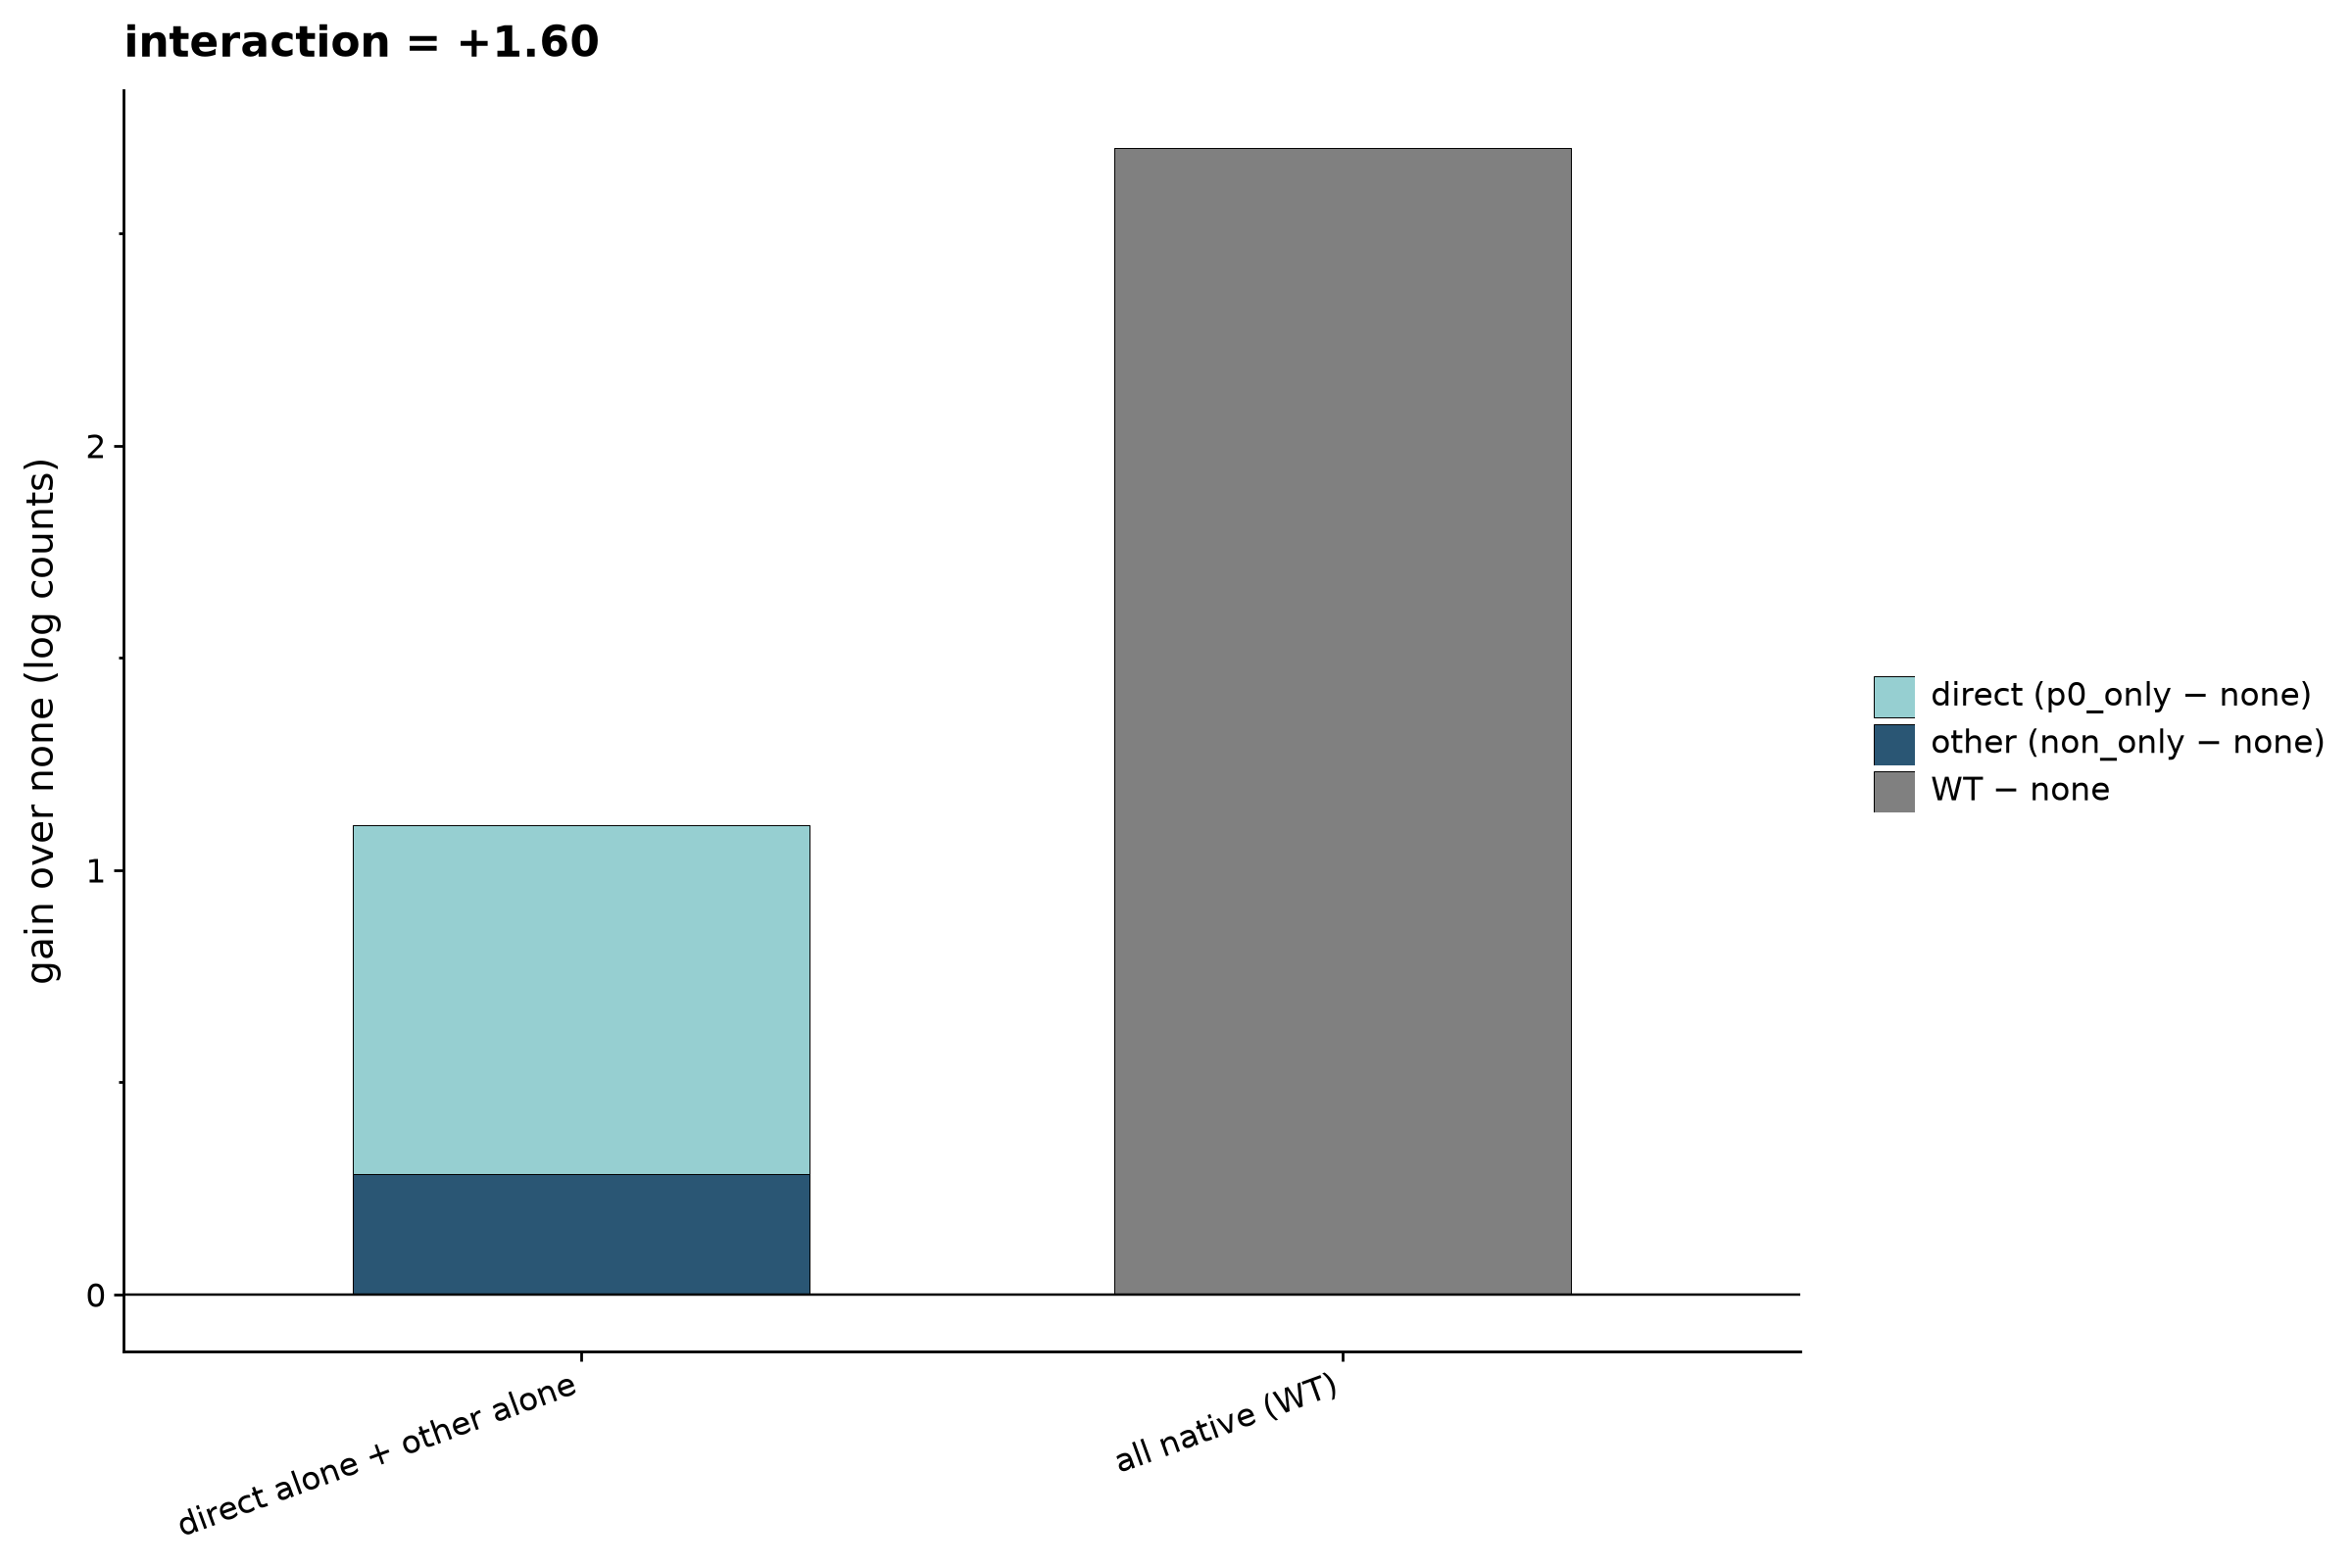

/home/labs/barkailab/vovam/miniconda/envs/seqtfun031/lib/python3.12/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 12 x 8 in image.
/home/labs/barkailab/vovam/miniconda/envs/seqtfun031/lib/python3.12/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: /home/labs/barkailab/vovam/submission_git/bpnet_grammar_paper/figures/FOXA1_self_vs_others_epi_synergy_barplots.pdf


In [6]:
# gains over `none`: direct alone + other alone (stacked) vs intact; WT bar taller -> synergy
p = gain_bars(df.loc[SYNERGY_PEAK], teals)
p.show()
p.save(fig_path('FOXA1_self_vs_others_epi_synergy_barplots.pdf'))

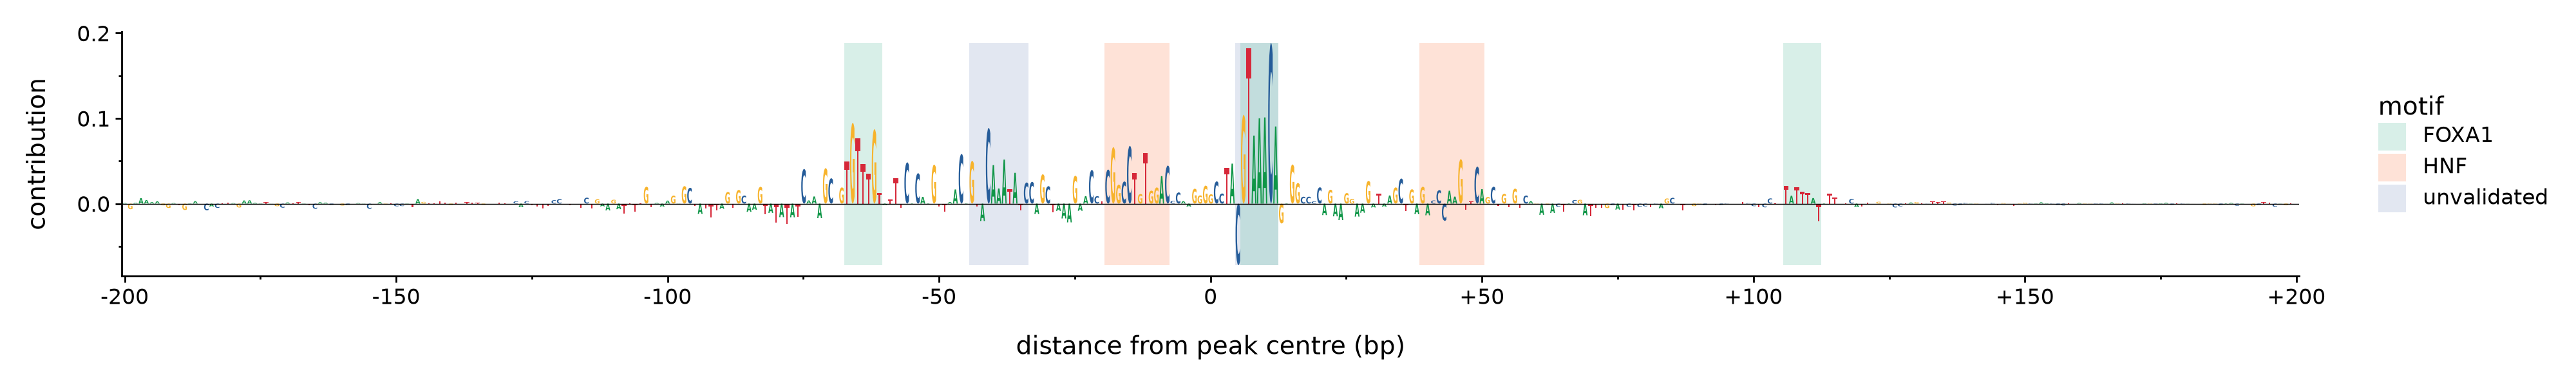

/home/labs/barkailab/vovam/miniconda/envs/seqtfun031/lib/python3.12/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 20 x 3 in image.
/home/labs/barkailab/vovam/miniconda/envs/seqtfun031/lib/python3.12/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: /home/labs/barkailab/vovam/submission_git/bpnet_grammar_paper/figures/FOXA1_self_vs_others_epi_additivity_seqlets.pdf


In [7]:
p = attribution_logo(peak_interval(df.loc[ADDITIVE_PEAK]), foxa1['hits'], foxa1['cfolds'])     # GPU
p.show()
p.save(fig_path('FOXA1_self_vs_others_epi_additivity_seqlets.pdf'))

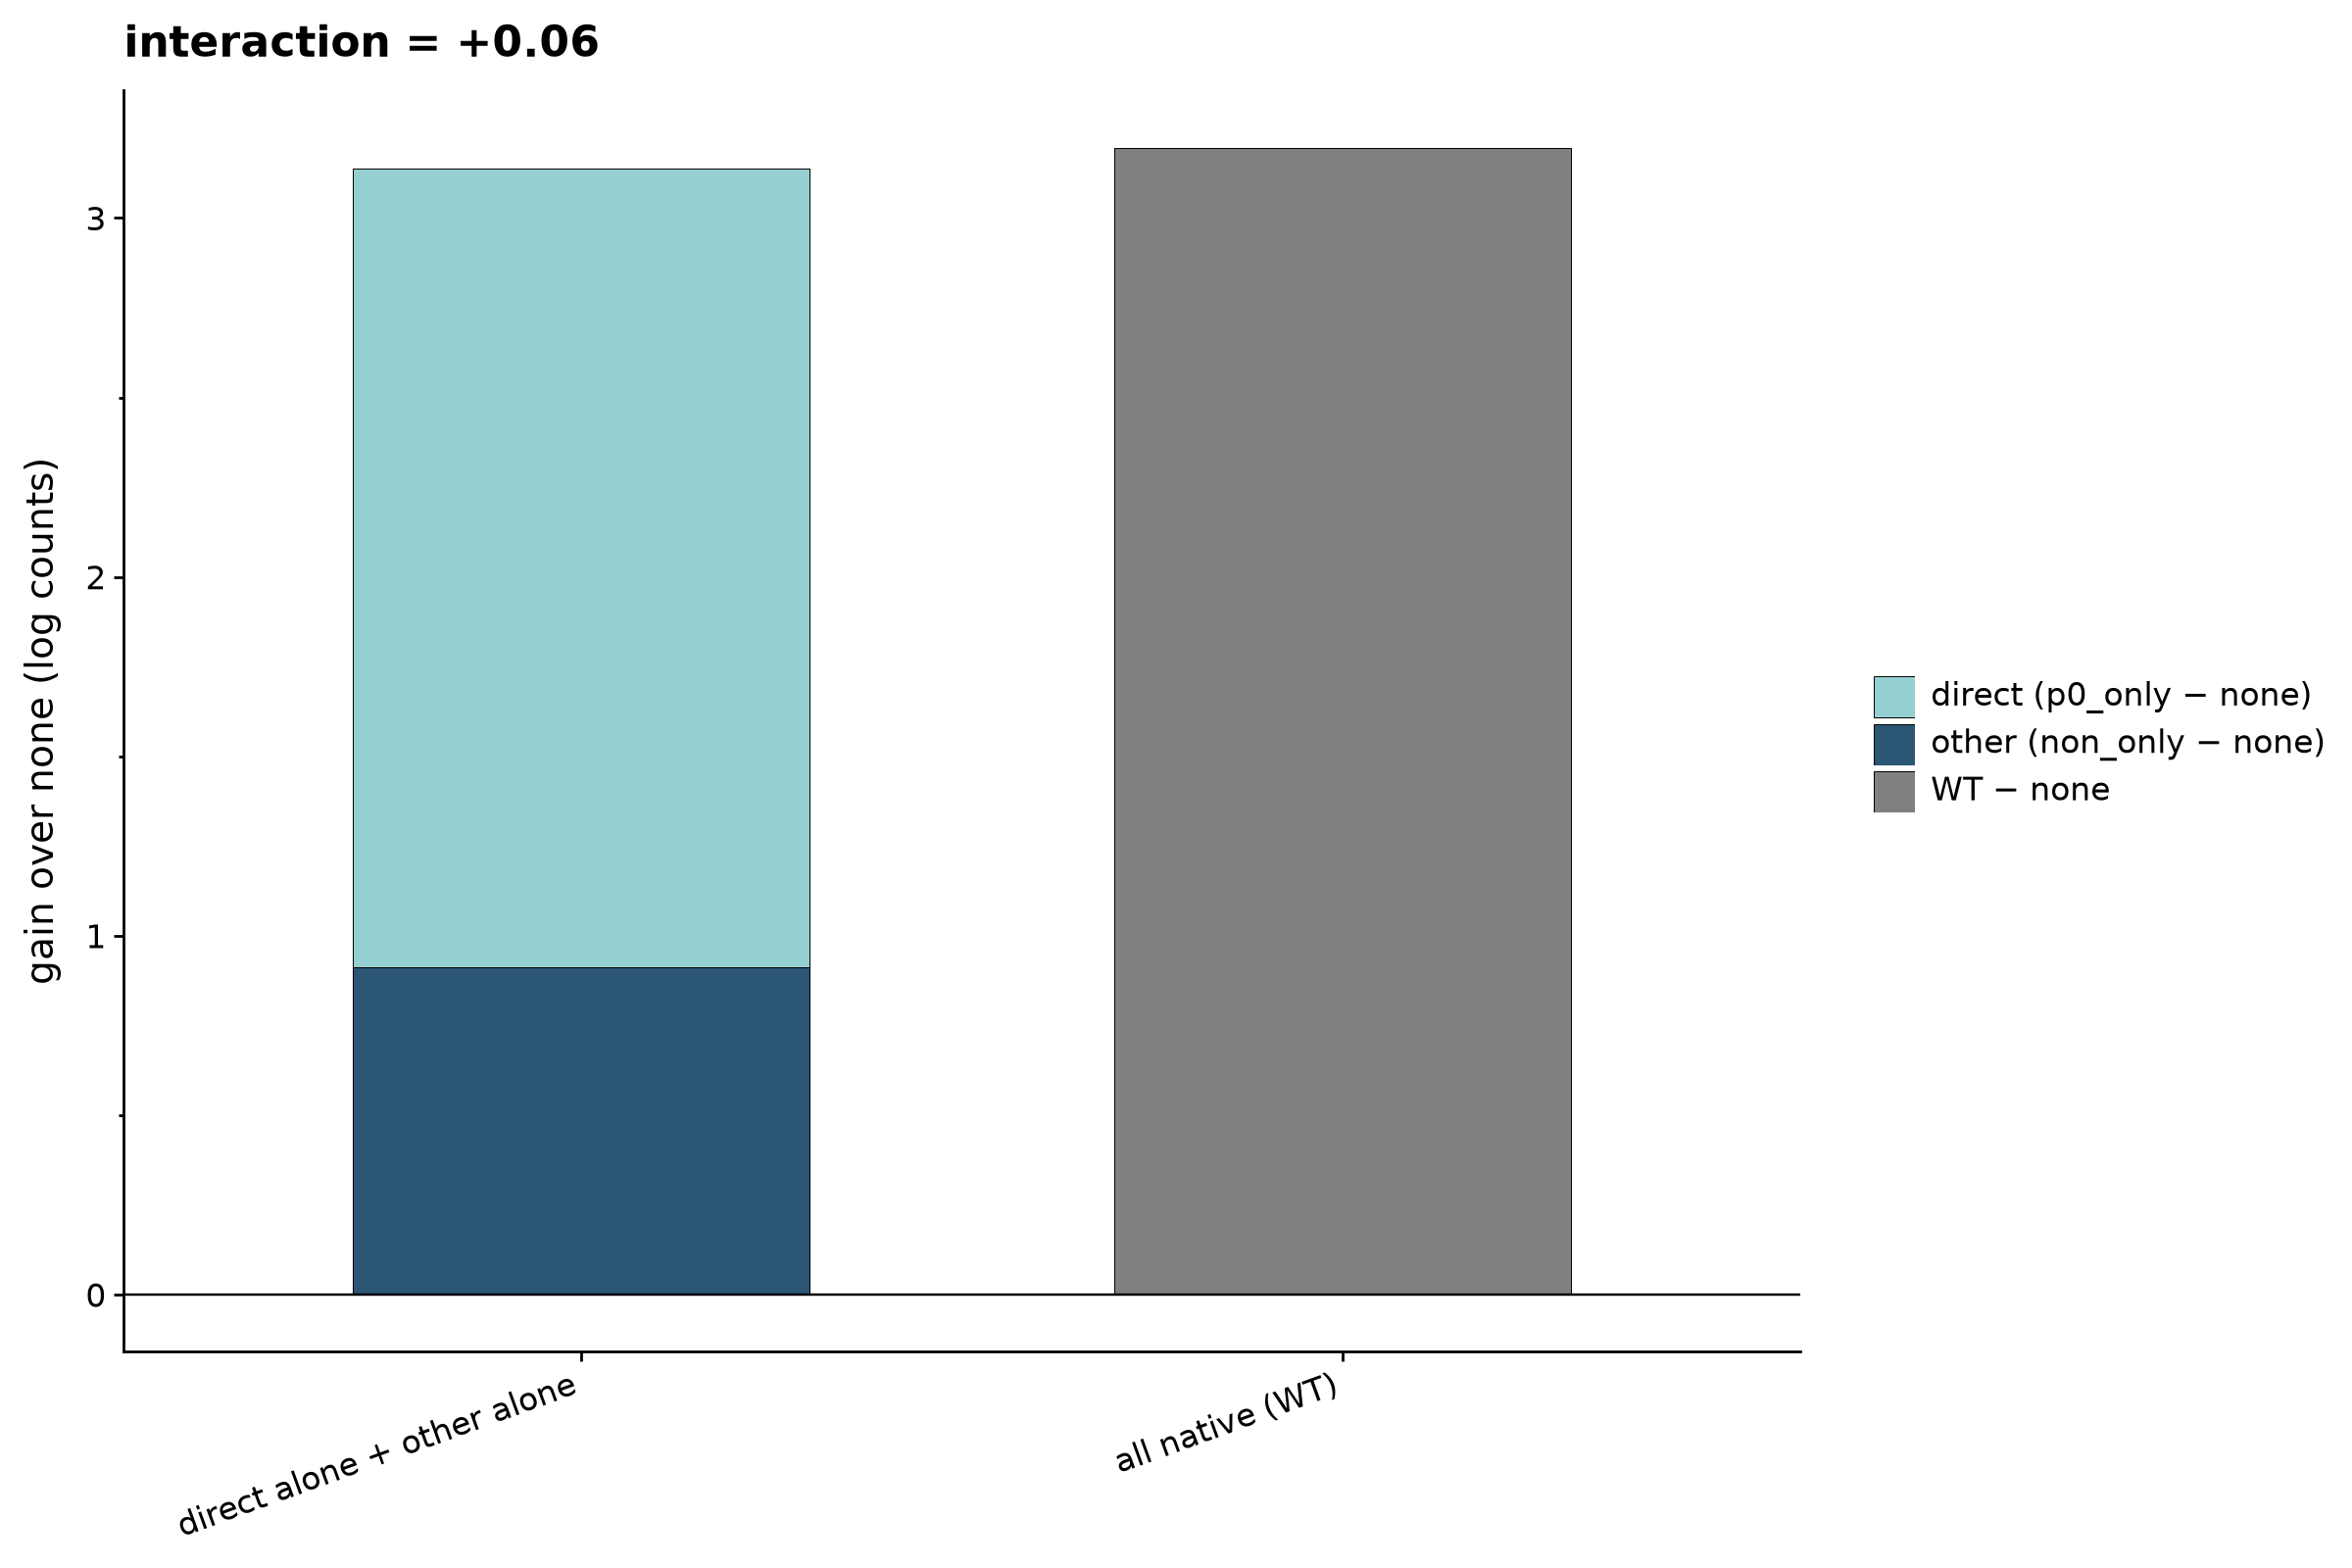

/home/labs/barkailab/vovam/miniconda/envs/seqtfun031/lib/python3.12/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 12 x 8 in image.
/home/labs/barkailab/vovam/miniconda/envs/seqtfun031/lib/python3.12/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: /home/labs/barkailab/vovam/submission_git/bpnet_grammar_paper/figures/FOXA1_self_vs_others_epi_additivity_bar.pdf


In [8]:
p = gain_bars(df.loc[ADDITIVE_PEAK], teals)
p.show()
p.save(fig_path('FOXA1_self_vs_others_epi_additivity_bar.pdf'))

## Generality: epistasis across all TFs
Per experiment, the fraction of peaks (with both direct and other motifs) whose interaction is ≥ t; one curve per
TF = mean over its experiments.

1480 experiments, 538 TFs


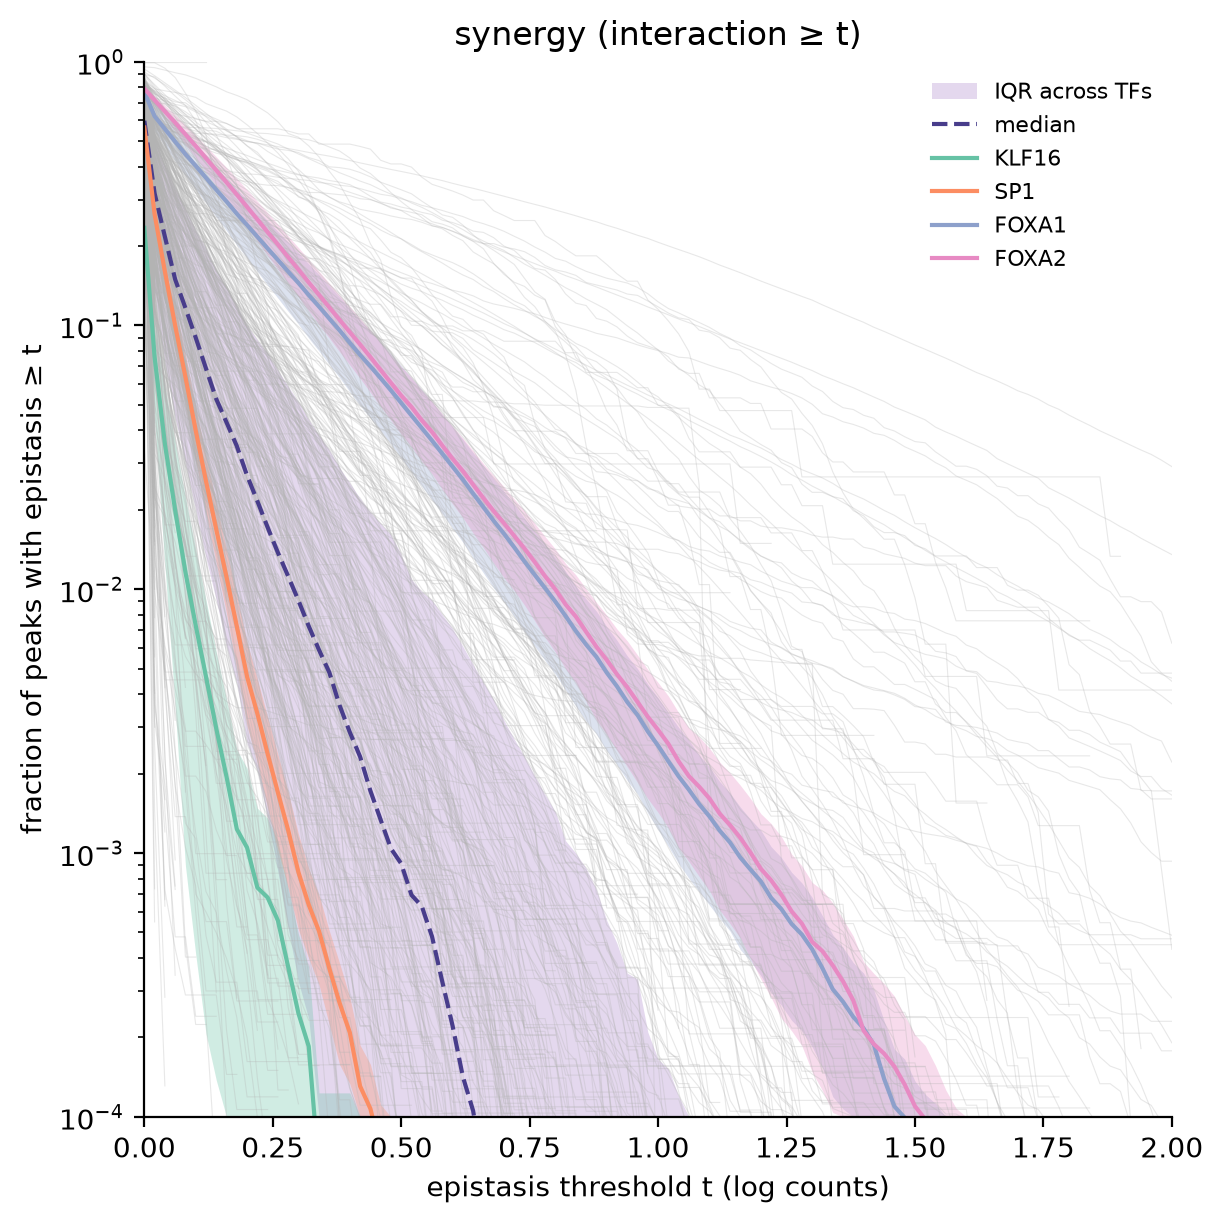

In [9]:
curves_pos = pd.read_parquet(paths.DATA / 'epi_curves_pos.parquet')
per_tf_pos, per_tf_pos_sem = per_tf(curves_pos)
print(len(curves_pos), 'experiments,', len(per_tf_pos), 'TFs')

fig, ax = plt.subplots(1, figsize=(6, 6), constrained_layout=True)
plot_epi_curves(per_tf_pos, ax=ax, logy=True, sem=per_tf_pos_sem, highlight=HIGHLIGHT)
ax.set_title('synergy (interaction ≥ t)')
plt.show()
fig.savefig(fig_path('curves.pdf'), dpi=300)

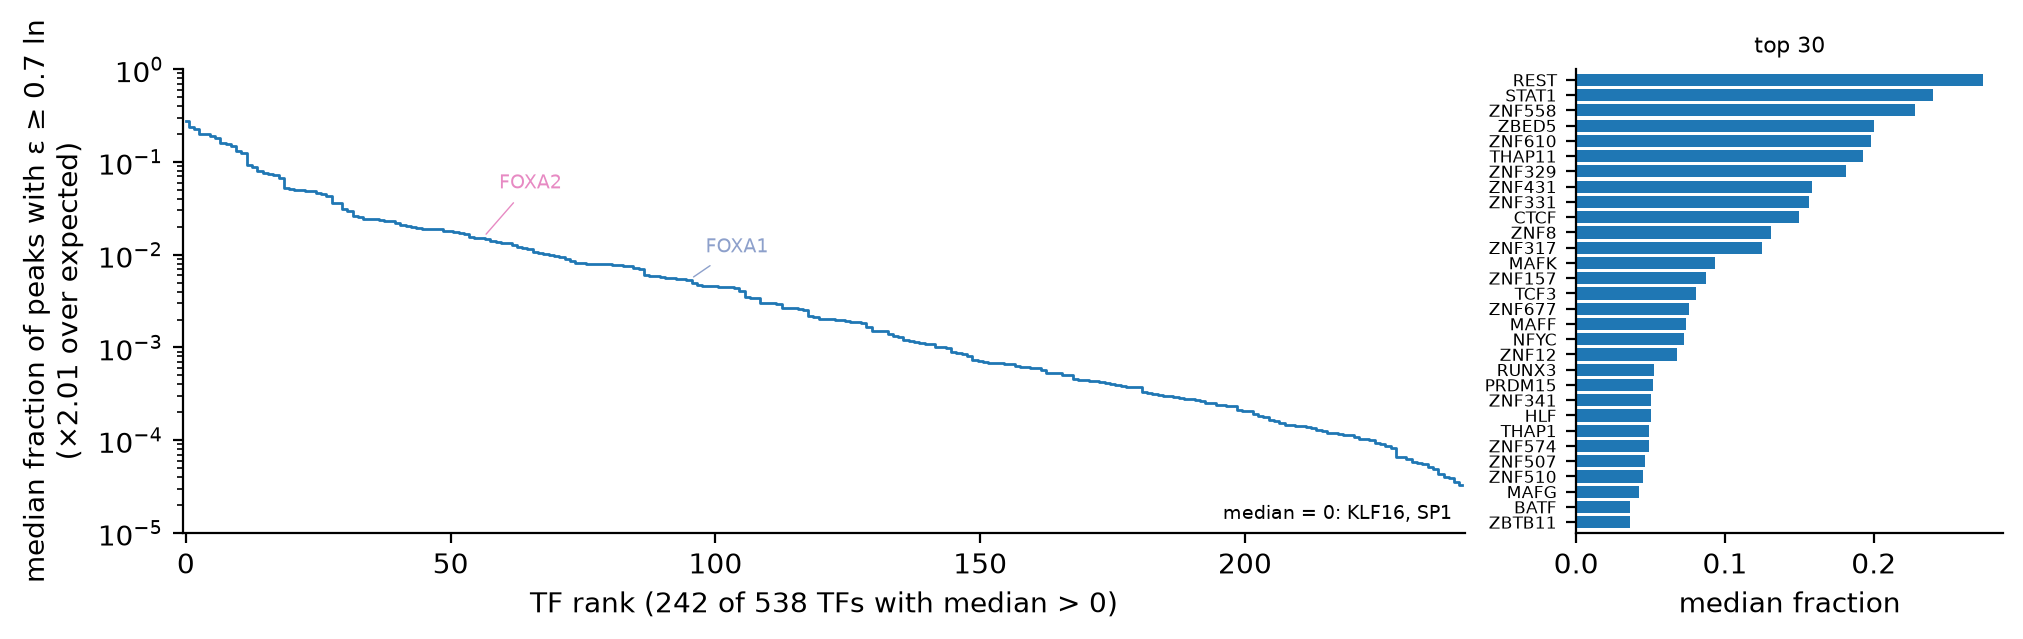

In [10]:
fig, ranked = plot_rank(curves_pos, col='0.7', top_n=30)
plt.show()
fig.savefig(fig_path('epi07_rank.pdf'))

## Effect of the direct motifs alone vs the other motifs alone
Per experiment, the fraction of peaks with p0_only − none ≥ t (direct) and with non_only − none ≥ t (others).

/home/labs/barkailab/vovam/miniconda/envs/seqtfun031/lib/python3.12/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 10 x 10 in image.
/home/labs/barkailab/vovam/miniconda/envs/seqtfun031/lib/python3.12/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: /home/labs/barkailab/vovam/submission_git/bpnet_grammar_paper/figures/dir_vs_others_ts.pdf


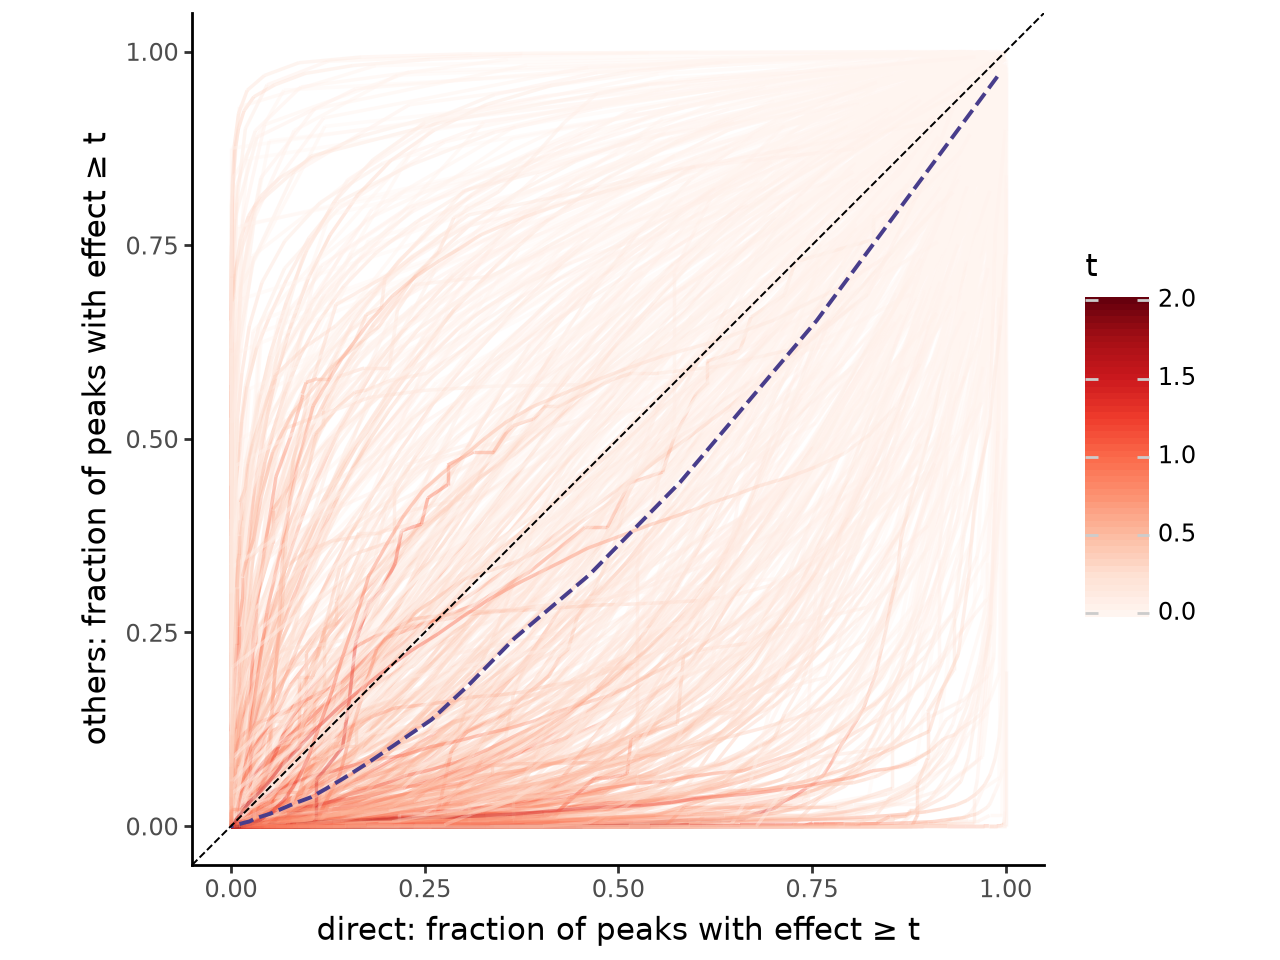

In [11]:
curves_effect = {k: pd.read_parquet(paths.DATA / f'effect_curves_{k}.parquet') for k in ('direct', 'others')}
th_eff_cols = TH_EFF.astype(str).tolist()
per_tf_effect = {k: per_tf(c, TH_EFF)[0] for k, c in curves_effect.items()}

long = (pd.concat({k: per_tf_effect[k].unstack() for k in ('direct', 'others')}, axis=1)
          .rename_axis(['t', 'tf']).reset_index())
long['t'] = long['t'].astype(float)
long = long.sort_values(['tf', 't'])

q = (long.groupby('t')[['direct', 'others']]
         .agg([lambda s: s.quantile(.25), 'median', lambda s: s.quantile(.75), 'mean']))
q.columns = [f'{c}_{s}' for c in ('direct', 'others') for s in ('q25', 'med', 'q75', 'mean')]
q = q.reset_index().sort_values('t')

p = (
    ggplot()
    + rasterise(geom_path(long, aes('direct', 'others', group='tf', color='t'), alpha=.4, size=.7), dpi=160)
    + geom_path(q, aes('direct_med', 'others_med'), color='darkslateblue', size=.8, linetype='dashed')
    + geom_abline(linetype='dashed', size=.4)
    + scale_color_cmap(cmap_name='Reds', limits=(0, 2))
    + coord_fixed()
    + labs(x='direct: fraction of peaks with effect ≥ t', y='others: fraction of peaks with effect ≥ t', color='t')
    + theme_classic()
    + guides(color=guide_colorbar(display='rectangles', nbin=50))
)
p.save(fig_path('dir_vs_others_ts.pdf'), width=10, height=10, units='in', dpi=300)
p.show()

/home/labs/barkailab/vovam/miniconda/envs/seqtfun031/lib/python3.12/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 8 x 5 in image.
/home/labs/barkailab/vovam/miniconda/envs/seqtfun031/lib/python3.12/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: /home/labs/barkailab/vovam/submission_git/bpnet_grammar_paper/figures/effect_log2ratio.pdf


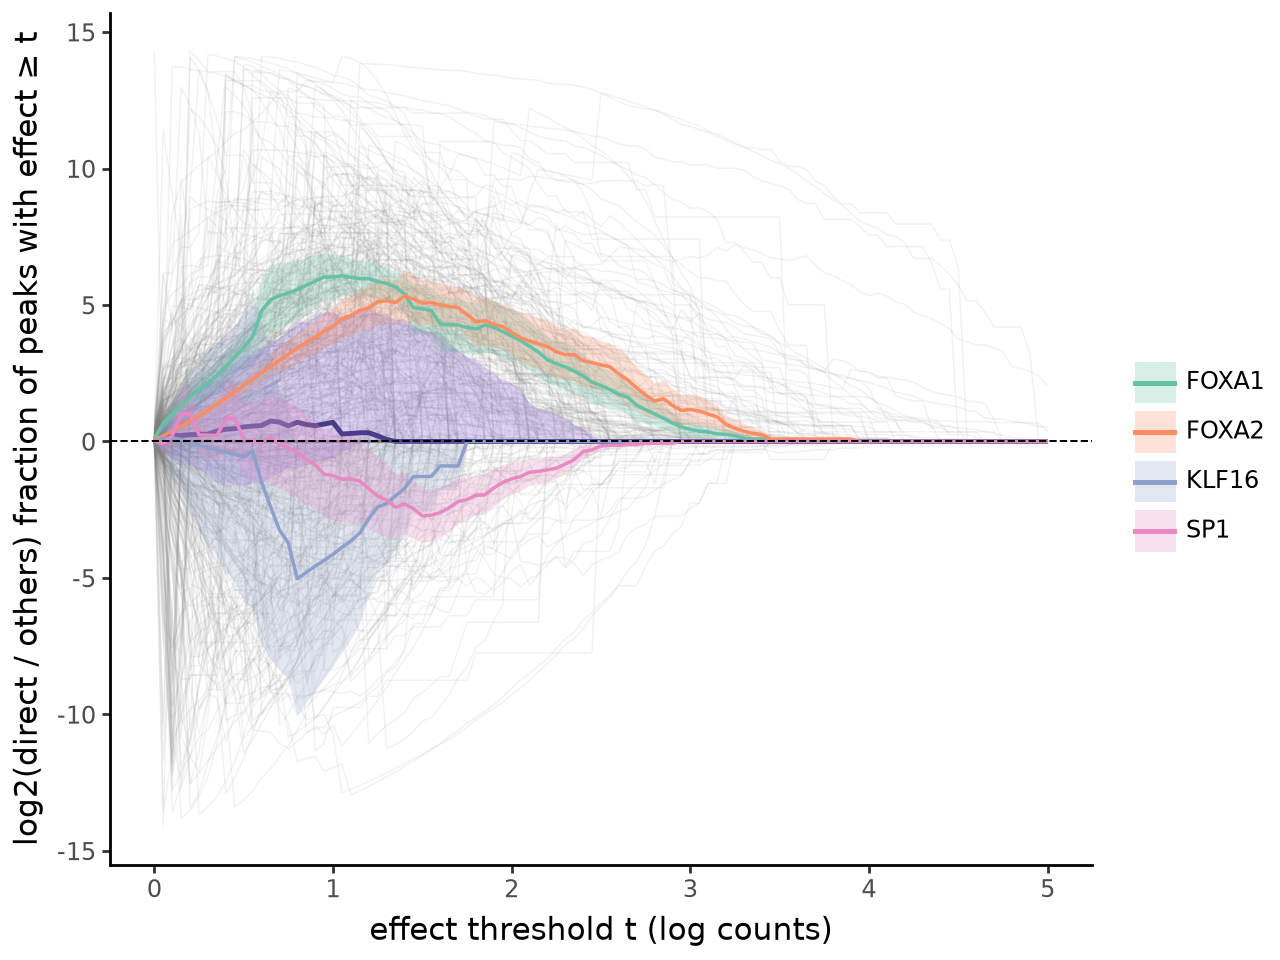

In [12]:
eps = 5e-05      # pseudocount, ~1 / typical number of peaks
T_MAX = 5.0      # beyond this both fractions approach 0 and the ratio is meaningless
keys = ['set', 'cell', 'exp', 'tf']

# per-experiment log2(direct / others), then mean and SEM over each TF's experiments
d = curves_effect['direct'].set_index(keys)[th_eff_cols]
o = curves_effect['others'].set_index(keys)[th_eff_cols]
d, o = d.align(o, join='inner')
ratio = np.log2((d + eps) / (o + eps))
ratio.columns = ratio.columns.astype(float)
ratio = ratio.loc[:, ratio.columns <= T_MAX]

g = ratio.groupby(level='tf')
long_r = pd.concat({'log2_ratio': g.mean().stack(), 'sem': g.sem().stack()}, axis=1)
long_r = long_r.rename_axis(['tf', 't']).reset_index()

r = (long_r.groupby('t')['log2_ratio'].quantile([.25, .5, .75]).unstack()
           .set_axis(['q25', 'med', 'q75'], axis=1).reset_index())       # median + IQR across TFs
hl = long_r[long_r.tf.isin(HIGHLIGHT)].copy()                            # highlighted TFs ± SEM
hl['lo'] = hl.log2_ratio - hl['sem']
hl['hi'] = hl.log2_ratio + hl['sem']

p_ratio = (
    ggplot()
    + rasterise(geom_line(long_r, aes('t', 'log2_ratio', group='tf'), color='grey', alpha=.1, size=.3), dpi=200)
    + geom_ribbon(r, aes('t', ymin='q25', ymax='q75'), fill='mediumpurple', alpha=.3)
    + geom_line(r, aes('t', 'med'), color='darkslateblue', size=1)
    + geom_ribbon(hl, aes('t', ymin='lo', ymax='hi', fill='tf'), alpha=.25)
    + geom_line(hl, aes('t', 'log2_ratio', color='tf'), size=.7)
    + geom_hline(yintercept=0, linetype='dashed', size=.4)
    + scale_color_brewer(type='qual', palette='Set2')
    + scale_fill_brewer(type='qual', palette='Set2')
    + labs(x='effect threshold t (log counts)', y='log2(direct / others) fraction of peaks with effect ≥ t',
           color='', fill='')
    + theme_classic()
)
p_ratio.save(fig_path('effect_log2ratio.pdf'), width=8, height=5, units='in', dpi=300)
p_ratio.show()